# Chapter 5: Classification
**Practical Statistics for Data Scientists (2nd Edition)** — Peter Bruce, Andrew Bruce & Peter Gedeck (O'Reilly)

Notebook ini berisi **reproduksi kode** dan **penjelasan teori** dari Chapter 5. Semua kode Python dari buku dijalankan ulang menggunakan dataset resmi buku (data pinjaman LendingClub), lalu setiap bagian diberi ringkasan konsep dan interpretasi hasil.

## Ringkasan Chapter
Klasifikasi adalah bentuk *supervised learning* yang tujuannya memprediksi apakah sebuah record termasuk kelas **1** atau **0** (misalnya *default / paid off*, *phishing / bukan*, *churn / tidak*), atau salah satu dari beberapa kategori. Hal yang sering lebih berguna daripada label biner adalah **propensity score**, yaitu probabilitas sebuah record masuk ke kelas yang diminati. Probabilitas ini lalu diubah menjadi keputusan lewat **cutoff**.

Alur umum klasifikasi dengan cutoff:
1. Tentukan cutoff probabilitas untuk kelas yang diminati.
2. Estimasi probabilitas record tersebut dengan model apa pun.
3. Jika probabilitas > cutoff, record dimasukkan ke kelas yang diminati.

Semakin tinggi cutoff, semakin sedikit record yang diprediksi sebagai 1. Semakin rendah cutoff, semakin banyak.

Chapter ini membahas lima topik:

| Bagian | Inti |
|---|---|
| Naive Bayes | Klasifikasi berbasis probabilitas bersyarat dengan asumsi independensi antarprediktor |
| Discriminant Analysis (LDA) | Mencari kombinasi linear prediktor yang memisahkan kelas sejauh mungkin |
| Logistic Regression & GLM | Model linear untuk *log-odds*, dipetakan kembali menjadi probabilitas |
| Evaluating Classification Models | Confusion matrix, precision, recall, specificity, ROC, AUC, lift |
| Strategies for Imbalanced Data | Undersampling, oversampling, weighting, SMOTE, cost-based classification |

> **Catatan multikelas.** Jika respons punya lebih dari dua kategori, masalahnya sering bisa diubah menjadi serangkaian masalah biner dengan probabilitas bersyarat. Contoh: (1) apakah pelanggan churn? (2) jika tidak churn, kontrak jenis apa yang dipilih? Cara ini terutama berguna ketika satu kategori jauh lebih umum daripada yang lain.

## 0. Setup dan Persiapan Data

Dataset yang dipakai pada chapter ini:

| File | Isi |
|---|---|
| `loan_data.csv.gz` | 45.342 pinjaman LendingClub, **seimbang** (50% default, 50% paid off) |
| `loan3000.csv` | Sampel 3.000 pinjaman dengan variabel `borrower_score` dan `payment_inc_ratio` |
| `full_train_set.csv.gz` | Data latih **lengkap dan tidak seimbang** (sekitar 19% default), dipakai pada bagian *imbalanced data* |

Variabel penting: `outcome` (*paid off* / *default*), `payment_inc_ratio` (rasio cicilan terhadap pendapatan), `borrower_score` (skor kelayakan kredit 0 sampai 1), `purpose_`, `home_`, `emp_len_` (variabel kategorikal).

In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.naive_bayes import MultinomialNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support,
                             roc_curve, roc_auc_score, precision_recall_curve)

%matplotlib inline
pd.set_option('display.width', 120)

DATA = Path('data')
LOAN3000_CSV = DATA / 'loan3000.csv'
LOAN_DATA_CSV = DATA / 'loan_data.csv.gz'
FULL_TRAIN_SET_CSV = DATA / 'full_train_set.csv.gz'

In [2]:
# --- loan_data: data seimbang (50% default / 50% paid off)
loan_data = pd.read_csv(LOAN_DATA_CSV)
loan_data = loan_data.drop(columns=['Unnamed: 0', 'status'], errors='ignore')

# Ubah kolom string menjadi tipe kategori. Urutan kategori mengikuti abjad,
# sama seperti urutan `classes_` pada scikit-learn: ['default', 'paid off'].
for col in ['outcome', 'purpose_', 'home_', 'emp_len_']:
    loan_data[col] = loan_data[col].astype('category')

# --- loan3000: sampel 3000 pinjaman
loan3000 = pd.read_csv(LOAN3000_CSV)
loan3000 = loan3000.drop(columns=['Unnamed: 0'], errors='ignore')
loan3000['outcome'] = loan3000['outcome'].astype('category')

# --- full_train_set: data lengkap, tidak seimbang
full_train_set = pd.read_csv(FULL_TRAIN_SET_CSV)
full_train_set = full_train_set.drop(columns=['Unnamed: 0'], errors='ignore')
for col in ['outcome', 'purpose_', 'home_', 'emp_len_']:
    full_train_set[col] = full_train_set[col].astype('category')

print('loan_data      :', loan_data.shape)
print('loan3000       :', loan3000.shape)
print('full_train_set :', full_train_set.shape)
loan_data.head()

loan_data      : (45342, 19)
loan3000       : (3000, 5)
full_train_set : (119987, 19)


,loan_amnt,term,annual_inc,dti,payment_inc_ratio,revol_bal,revol_util,purpose,home_ownership,delinq_2yrs_zero,pub_rec_zero,open_acc,grade,outcome,emp_length,purpose_,home_,emp_len_,borrower_score
0,2500,60 months,30000,1.00,2.39320,1687,9.4,car,RENT,1,1,3,4.8,default,1,major_purchase,RENT,> 1 Year,0.65
1,5600,60 months,40000,5.55,4.57170,5210,32.6,small_business,OWN,1,1,11,1.4,default,5,small_business,OWN,> 1 Year,0.80
2,5375,60 months,15000,18.08,9.71600,9279,36.5,other,RENT,1,1,2,6.0,default,1,other,RENT,> 1 Year,0.60
3,9000,36 months,30000,10.08,12.21520,10452,91.7,debt_consolidation,RENT,1,1,4,4.2,default,1,debt_consolidation,RENT,> 1 Year,0.50
4,10000,36 months,100000,7.06,3.90888,11997,55.5,other,RENT,1,1,14,5.4,default,4,other,RENT,> 1 Year,0.55


---
## 1. Naive Bayes

### Teori

Algoritma **Naive Bayes** memakai probabilitas *mengamati nilai-nilai prediktor, jika diketahui hasilnya*, untuk mengestimasi yang sebenarnya dicari: probabilitas *hasil $Y = i$, jika diketahui nilai-nilai prediktor*.

**Istilah kunci**
- **Conditional probability (probabilitas bersyarat):** peluang suatu kejadian jika kejadian lain sudah diketahui, ditulis $P(X_j \mid Y = i)$.
- **Posterior probability:** peluang hasil *setelah* informasi prediktor dimasukkan (kebalikan dari *prior*, yaitu peluang hasil tanpa informasi prediktor).

**Exact Bayesian classification.** Untuk setiap record baru: (1) cari semua record training yang profil prediktornya identik, (2) lihat kelas yang paling banyak muncul di antara record tersebut, (3) berikan kelas itu pada record baru. Cara ini **tidak praktis**. Begitu jumlah prediktor lebih dari segelintir, hampir tidak ada record yang cocok persis. Menambah satu variabel dengan 5 kategori yang sama sering muncul menurunkan peluang menemukan kecocokan sebanyak 5 kali lipat.

**Solusi "naive".** Perhitungan tidak lagi dibatasi pada record yang cocok persis, tetapi memakai seluruh data:
1. Untuk tiap prediktor, estimasi $P(X_j \mid Y = i)$ sebagai proporsi nilai $X_j$ di antara record dengan $Y = i$.
2. Kalikan probabilitas-probabilitas itu, lalu kalikan dengan proporsi record kelas $i$ (prior).
3. Ulangi untuk semua kelas.
4. Bagi nilai tiap kelas dengan jumlah nilai semua kelas, sehingga menjadi probabilitas.
5. Pilih kelas dengan probabilitas tertinggi.

Rumus dengan asumsi independensi bersyarat:

$$P(Y=i \mid X_1,\dots,X_p) = \frac{P(Y=i)\,P(X_1 \mid Y=i)\cdots P(X_p \mid Y=i)}{\sum_{k} P(Y=k)\,P(X_1 \mid Y=k)\cdots P(X_p \mid Y=k)}$$

Disebut *naive* karena kita mengasumsikan setiap $X_j$ independen terhadap prediktor lain jika kelasnya diketahui. Asumsi ini jarang benar, tetapi untuk tujuan **meranking** record berdasarkan probabilitas $Y=1$, hasilnya tetap baik. Estimasi probabilitas dari Naive Bayes diketahui **bias**.

**Poin penting**
- Naive Bayes standar hanya bekerja dengan prediktor **kategorikal**. Prediktor numerik harus di-*binning* atau dimodelkan dengan distribusi probabilitas (misalnya normal).
- Jika suatu kategori tidak pernah muncul pada data training untuk kelas tertentu, probabilitasnya menjadi 0 dan menghapus semua informasi prediktor lain. Karena itu implementasi umumnya memakai **Laplace smoothing** (parameter `alpha` pada scikit-learn).

### Kode
Kita memakai `MultinomialNB`. Variabel kategorikal diubah dulu menjadi dummy variable.

In [3]:
predictors = ['purpose_', 'home_', 'emp_len_']
outcome = 'outcome'
X = pd.get_dummies(loan_data[predictors], prefix='', prefix_sep='', dtype=int)
y = loan_data[outcome]

naive_model = MultinomialNB(alpha=0.01, fit_prior=True)
naive_model.fit(X, y)
print('classes_:', list(naive_model.classes_))

classes_: [np.str_('default'), np.str_('paid off')]


Pada versi R, tabel `naive_model$table` menampilkan $P(X_j \mid Y)$ per variabel. Di scikit-learn, `feature_log_prob_` menyimpan log probabilitas tersebut, tetapi dinormalisasi terhadap **seluruh dummy sekaligus** (bukan per variabel). Untuk membandingkan dengan tabel pada buku, kita bisa menghitung proporsi per variabel secara langsung.

In [4]:
# P(X_j | Y) per variabel, setara dengan tabel `naive_model$table` di R
for var in predictors:
    print(f'--- P({var} | outcome)')
    print(pd.crosstab(loan_data[outcome], loan_data[var], normalize='index').round(4))
    print()

--- P(purpose_ | outcome)
purpose_  credit_card  debt_consolidation  home_improvement  major_purchase  medical   other  small_business
outcome                                                                                                     
default        0.1515              0.5757            0.0598          0.0373   0.0143  0.1156          0.0457
paid off       0.1876              0.5522            0.0715          0.0536   0.0142  0.0999          0.0210

--- P(home_ | outcome)
home_     MORTGAGE     OWN    RENT
outcome                           
default     0.4313  0.0833  0.4854
paid off    0.4895  0.0809  0.4296

--- P(emp_len_ | outcome)
emp_len_  < 1 Year  > 1 Year
outcome                     
default     0.0473    0.9527
paid off    0.0311    0.9689



Sekarang kita prediksi pinjaman baru. Seperti pada buku, kita ambil satu record dari data (baris ke-147, indeks 146) sebagai pinjaman yang akan diuji.

In [5]:
new_loan = X.loc[146:146, :]
print(loan_data.loc[146, predictors].to_dict())

print('predicted class: ', naive_model.predict(new_loan)[0])

probabilities = pd.DataFrame(naive_model.predict_proba(new_loan),
                             columns=loan_data[outcome].cat.categories)
print('predicted probabilities')
print(probabilities)

{'purpose_': 'small_business', 'home_': 'MORTGAGE', 'emp_len_': ' > 1 Year'}
predicted class:  default
predicted probabilities
    default  paid off
0  0.653696  0.346304


**Verifikasi manual.** Agar rumus di atas terasa konkret, kita hitung posterior untuk record yang sama secara langsung: prior kelas dikalikan probabilitas bersyarat tiap prediktor, lalu dinormalisasi.

In [6]:
row = loan_data.loc[146, predictors]
scores = {}
for cls in loan_data[outcome].cat.categories:
    sub = loan_data[loan_data[outcome] == cls]
    score = len(sub) / len(loan_data)              # prior P(Y = cls)
    for var in predictors:
        score *= (sub[var] == row[var]).mean()      # P(X_j = nilai | Y = cls)
    scores[cls] = score

total = sum(scores.values())
posterior = {cls: s / total for cls, s in scores.items()}
print('posterior (hitung manual):', {k: round(v, 4) for k, v in posterior.items()})

posterior (hitung manual): {'default': np.float64(0.6537), 'paid off': np.float64(0.3463)}


**Interpretasi hasil:**
- Tabel proporsi di atas identik dengan tabel `naive_model$table` pada versi R di buku. Contoh: peminjam `small_business` berjumlah 4,57% di antara pinjaman *default* tetapi hanya 2,10% di antara pinjaman *paid off*; peminjam `RENT` 48,5% (default) vs 43,0% (paid off).
- Untuk pinjaman baru (`small_business`, `MORTGAGE`, `> 1 Year`), model memprediksi **default** dengan probabilitas posterior **0,654** (paid off 0,346), sama dengan hasil R pada buku.
- Perhitungan manual (prior × probabilitas bersyarat, lalu normalisasi) menghasilkan angka yang sama persis dengan `predict_proba`. Ini menunjukkan bahwa Naive Bayes pada dasarnya hanyalah perkalian proporsi.
- Ingat bahwa estimasi probabilitas Naive Bayes cenderung bias. Model ini paling cocok bila tujuannya meranking record, bukan menaksir probabilitas yang akurat.

---
## 2. Discriminant Analysis

### Teori

*Discriminant analysis* adalah pengklasifikasi statistik tertua, diperkenalkan oleh R. A. Fisher pada 1936. Bentuk yang paling umum adalah **Linear Discriminant Analysis (LDA)**. Saat ini LDA lebih jarang dipakai dibanding model pohon dan regresi logistik, tetapi masih relevan karena berkaitan dengan metode lain seperti PCA.

> LDA di sini adalah *Linear Discriminant Analysis*, **bukan** *Latent Dirichlet Allocation* yang dipakai di NLP.

**Istilah kunci**
- **Covariance:** ukuran seberapa besar dua variabel bergerak bersama (magnitudo dan arah).
- **Discriminant function:** fungsi atas prediktor yang memaksimalkan pemisahan kelas.
- **Discriminant weights:** skor hasil fungsi diskriminan, dipakai untuk mengestimasi probabilitas keanggotaan kelas.

**Kovarians dan matriks kovarians.** Untuk dua variabel $x$ dan $z$:

$$s_{x,z} = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(z_i-\bar{z})}{n-1}$$

Berbeda dengan korelasi yang terbatas pada $[-1, 1]$, skala kovarians bergantung pada skala variabel. Matriks kovarians $\Sigma$ berisi varians masing-masing variabel pada diagonal dan kovarians antarpasangan di luar diagonal. Matriks ini adalah perluasan multivariat dari standardisasi *z-score* dan berkaitan dengan **jarak Mahalanobis**.

**Fisher's linear discriminant.** Untuk dua kelompok (y = 0 dan y = 1), LDA mencari kombinasi linear $w_x x + w_z z$ yang memaksimalkan rasio antara variasi **antar-kelompok** dan variasi **dalam-kelompok**:

$$\frac{SS_{between}}{SS_{within}}$$

$SS_{between}$ adalah kuadrat jarak antara rerata kedua kelompok, sedangkan $SS_{within}$ adalah sebaran di sekitar rerata tiap kelompok yang dibobot dengan matriks kovarians. Dengan memaksimalkan rasio ini, pemisahan kedua kelompok menjadi paling besar.

**Asumsi.** Secara teknis prediktor diasumsikan berdistribusi normal, tetapi dalam praktik metode ini bekerja baik pada penyimpangan normalitas yang tidak ekstrem dan pada prediktor biner.

**Ekstensi**
- LDA bisa dipakai dengan lebih dari dua prediktor. Batasnya adalah jumlah record untuk mengestimasi matriks kovarians.
- **QDA (Quadratic Discriminant Analysis):** matriks kovarians boleh berbeda untuk tiap kelompok. Pada LDA, matriks kovarians diasumsikan sama.
- Jika prediktor dinormalisasi lebih dulu, bobot diskriminan dapat dibaca sebagai ukuran **kepentingan variabel**, sehingga LDA bisa dipakai sebagai seleksi fitur yang efisien.

### Kode

In [7]:
predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_lda = LinearDiscriminantAnalysis()
loan_lda.fit(X, y)
pd.DataFrame(loan_lda.scalings_, index=X.columns, columns=['LD1'])

,LD1
borrower_score,7.175839
payment_inc_ratio,-0.099676


In [8]:
pred = pd.DataFrame(loan_lda.predict_proba(loan3000[predictors]),
                    columns=loan_lda.classes_)
pred.head()

,default,paid off
0,0.553544,0.446456
1,0.558953,0.441047
2,0.272696,0.727304
3,0.506254,0.493746
4,0.609952,0.390048


Plot berikut menunjukkan cara kerja LDA. Garis hijau/biru adalah batas keputusan (probabilitas 0,5) yang dihitung dari bobot diskriminan dan titik tengah kedua rerata kelompok. Titik yang makin jauh dari garis memiliki probabilitas yang makin jauh dari 0,5, artinya prediksi makin yakin.

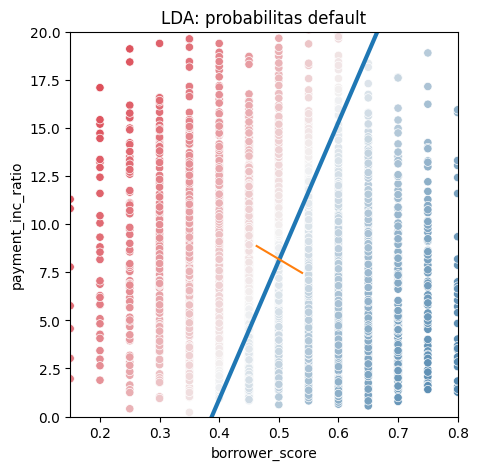

In [9]:
# Gunakan scalings dan titik tengah rerata untuk menentukan batas keputusan
center = np.mean(loan_lda.means_, axis=0)
slope = - loan_lda.scalings_[0] / loan_lda.scalings_[1]
intercept = center[1] - center[0] * slope

# nilai borrower_score untuk payment_inc_ratio = 0 dan 20
x_0 = (0 - intercept) / slope
x_20 = (20 - intercept) / slope

lda_df = pd.concat([loan3000, pred['default']], axis=1)

fig, ax = plt.subplots(figsize=(5, 5))
g = sns.scatterplot(x='borrower_score', y='payment_inc_ratio',
                    hue='default', data=lda_df,
                    palette=sns.diverging_palette(240, 10, n=9, as_cmap=True),
                    ax=ax, legend=False)

ax.set_ylim(0, 20)
ax.set_xlim(0.15, 0.8)
ax.plot((x_0, x_20), (0, 20), linewidth=3)
ax.plot(*loan_lda.means_.transpose())
ax.set_title('LDA: probabilitas default')
plt.show()

**Interpretasi hasil:**
- Bobot diskriminan: `borrower_score` = **7,176** dan `payment_inc_ratio` = **−0,0997**, sama dengan hasil R di buku. `borrower_score` yang tinggi mendorong prediksi ke *paid off*, sedangkan `payment_inc_ratio` yang tinggi sedikit mendorong ke *default*.
- Kedua bobot berada pada skala variabel yang berbeda, sehingga untuk membandingkan kepentingan variabel prediktor sebaiknya distandardisasi lebih dulu (seperti catatan buku tentang seleksi fitur).
- Pada plot, titik di sebelah kiri garis diprediksi *default* (probabilitas > 0,5). Warna merah pekat berarti probabilitas default tinggi, biru pekat berarti rendah. Titik yang semakin jauh dari garis memiliki probabilitas yang semakin jauh dari 0,5, artinya prediksi semakin yakin.

---
## 3. Logistic Regression dan GLM

### Teori

Regresi logistik analog dengan regresi linear berganda, tetapi **outcome-nya biner**. Berbeda dengan KNN dan Naive Bayes yang berbasis data, regresi logistik (seperti LDA) adalah pendekatan **berbasis model terstruktur**. Kecepatan komputasi dan kemudahan *scoring* data baru membuatnya sangat populer.

**Istilah kunci**
- **Logit:** fungsi yang memetakan probabilitas keanggotaan kelas ke rentang $\pm\infty$ (bukan hanya 0 sampai 1). Sinonim: *log odds*.
- **Odds:** rasio "sukses" (1) terhadap "bukan sukses" (0).
- **Log odds:** respons pada model yang sudah ditransformasi (sehingga linear), lalu dipetakan kembali menjadi probabilitas.

**Dari probabilitas ke log-odds.** Memodelkan $p = \beta_0 + \beta_1 x_1 + \dots$ secara langsung tidak menjamin $p$ berada di antara 0 dan 1. Karena itu dipakai *logistic response function* (inverse logit):

$$p = \frac{1}{1+e^{-(\beta_0+\beta_1x_1+\cdots+\beta_qx_q)}}$$

Agar bentuk eksponensial keluar dari penyebut, dipakai konsep **odds**:

$$\text{Odds}(Y=1) = \frac{p}{1-p} \qquad\qquad p = \frac{\text{Odds}}{1+\text{Odds}}$$

Dengan menggabungkan keduanya diperoleh $\text{Odds}(Y=1)=e^{\beta_0+\beta_1x_1+\cdots}$, dan setelah logaritma:

$$\log\big(\text{Odds}(Y=1)\big) = \beta_0+\beta_1x_1+\cdots+\beta_qx_q$$

Inilah fungsi **logit**. Ia memetakan $p \in (0,1)$ ke $(-\infty, +\infty)$, sehingga model linear bisa dipakai. Hasil prediksi kemudian diubah menjadi kelas dengan aturan cutoff.

**GLM (Generalized Linear Model).** Regresi logistik adalah kasus khusus GLM. GLM dicirikan oleh dua komponen: (1) **distribusi/family** probabilitas (*binomial* untuk regresi logistik) dan (2) **link function** yang memetakan respons ke prediktor (*logit* untuk regresi logistik). GLM lain yang sering ditemui: **Poisson** (data cacah), **negative binomial**, dan **gamma** (waktu sampai kejadian). Menurut buku, GLM selain logistik lebih rumit dan sebaiknya dihindari kecuali Anda memahami kegunaan dan jebakannya.

**Pemodelan variabel faktor.** Seperti pada regresi linear, variabel kategorikal dengan $P$ level dikodekan dengan $P-1$ kolom (reference coding) untuk menghindari multikolinearitas. Karena itu kita memakai `drop_first=True` pada `get_dummies`.

**Cara model dilatih: Maximum Likelihood Estimation (MLE).** Regresi logistik tidak punya solusi tertutup dan tidak bisa memakai *least squares*. MLE mencari parameter $\theta$ yang membuat data yang teramati paling mungkin muncul. Kualitas fit diukur dengan **deviance**:

$$\text{deviance} = -2\log P_\theta(X_1,\dots,X_n)$$

Deviance yang lebih rendah berarti fit yang lebih baik.

**Interpretasi koefisien dan odds ratio.** Untuk variabel biner $X$:

$$\text{odds ratio} = \frac{\text{Odds}(Y=1 \mid X=1)}{\text{Odds}(Y=1 \mid X=0)}$$

Koefisien $\beta_j$ adalah **log dari odds ratio** untuk $X_j$. Maka $e^{\beta_j}$ adalah odds ratio-nya. Jika odds ratio = 2, odds $Y=1$ dua kali lebih tinggi ketika $X=1$ dibanding $X=0$. Untuk variabel numerik, odds ratio menyatakan perubahan odds untuk kenaikan satu unit $X$.

### Kode
Perhatikan bahwa scikit-learn mengurutkan kelas secara abjad (`default`, `paid off`), kebalikan dari urutan faktor di R. Akibatnya **tanda koefisien terbalik** dibanding versi R. Regularisasi (L2) aktif secara default, jadi untuk fit tanpa regularisasi `C` diatur sangat besar.

In [10]:
predictors = ['payment_inc_ratio', 'purpose_', 'home_', 'emp_len_', 'borrower_score']
outcome = 'outcome'
X = pd.get_dummies(loan_data[predictors], prefix='', prefix_sep='',
                   drop_first=True, dtype=int)
y = loan_data[outcome]

# C sangat besar = praktis tanpa regularisasi (penalti default L2)
logit_reg = LogisticRegression(C=1e42, solver='liblinear')
logit_reg.fit(X, y)

print('classes_  :', list(logit_reg.classes_))
print('intercept :', round(logit_reg.intercept_[0], 5))
coef = pd.DataFrame({'coeff': logit_reg.coef_[0]}, index=X.columns)
coef

classes_  : ['default', 'paid off']
intercept : -1.63809


,coeff
payment_inc_ratio,-0.079728
borrower_score,4.611037
debt_consolidation,-0.249342
home_improvement,-0.407614
major_purchase,-0.229375
medical,-0.510087
other,-0.620534
small_business,-1.215662
OWN,-0.048453
RENT,-0.157355


Koefisien di atas adalah untuk kelas `paid off`. Untuk membacanya sebagai **risiko default** seperti pada buku, balik tandanya, lalu ambil eksponen untuk mendapatkan odds ratio.

In [11]:
odds = pd.DataFrame({
    'coef (default)': -logit_reg.coef_[0],
    'odds ratio': np.exp(-logit_reg.coef_[0]),
}, index=X.columns)
odds.round(4)

,coef (default),odds ratio
payment_inc_ratio,0.0797,1.0830
borrower_score,-4.6110,0.0099
debt_consolidation,0.2493,1.2832
home_improvement,0.4076,1.5032
major_purchase,0.2294,1.2578
medical,0.5101,1.6654
other,0.6205,1.8599
small_business,1.2157,3.3725
OWN,0.0485,1.0496
RENT,0.1574,1.1704


### Nilai prediksi dari regresi logistik

Prediksi mentah regresi logistik berada pada skala **log-odds** $\hat{Y}=\log\text{Odds}(Y=1)$. Probabilitas didapat dengan fungsi respons logistik:

$$p = \frac{1}{1+e^{-\hat{Y}}}$$

Berikut kita lihat distribusi log probabilitas dan probabilitas, lalu memverifikasi bahwa transformasi manual dari log-odds sama dengan `predict_proba`.

In [12]:
pred = pd.DataFrame(logit_reg.predict_log_proba(X),
                    columns=loan_data[outcome].cat.categories)
print('log probabilitas:')
print(pred.describe())

pred = pd.DataFrame(logit_reg.predict_proba(X),
                    columns=loan_data[outcome].cat.categories)
print('\nprobabilitas:')
print(pred.describe())

log probabilitas:
            default      paid off
count  45342.000000  45342.000000
mean      -0.757850     -0.760423
std        0.378032      0.390419
min       -2.768873     -3.538864
25%       -0.985728     -0.977164
50%       -0.697366     -0.688946
75%       -0.472209     -0.467076
max       -0.029476     -0.064787

probabilitas:
            default      paid off
count  45342.000000  45342.000000
mean       0.500001      0.499999
std        0.167336      0.167336
min        0.062733      0.029046
25%        0.373167      0.376377
50%        0.497895      0.502105
75%        0.623623      0.626833
max        0.970954      0.937267


In [13]:
# Verifikasi: log-odds -> probabilitas (kelas 'paid off')
log_odds = X.values @ logit_reg.coef_[0] + logit_reg.intercept_[0]
manual_prob = 1 / (1 + np.exp(-log_odds))
print('sama dengan predict_proba?',
      np.allclose(manual_prob, logit_reg.predict_proba(X)[:, 1]))

sama dengan predict_proba? True


**Interpretasi hasil:**
- Intersep −1,638 dan koefisien lainnya memiliki besaran yang sama dengan hasil R, tetapi **tanda terbalik** karena scikit-learn memodelkan kelas `paid off` (urutan abjad kedua), sedangkan R memodelkan `default`. Tabel odds ratio sudah membalik tanda tersebut agar bisa dibaca sebagai risiko default.
- `purpose_small_business` memiliki odds ratio **3,37** (≈ 3,4 pada buku): dibanding pinjaman untuk melunasi kartu kredit, pinjaman usaha kecil memiliki odds default sekitar 3,4 kali lebih tinggi.
- `borrower_score` memiliki odds ratio **0,0099** (≈ 0,01): peminjam dengan skor terbaik memiliki odds default sekitar 100 kali lebih kecil daripada peminjam dengan skor terburuk.
- `payment_inc_ratio` memiliki odds ratio **1,083**: setiap kenaikan satu unit rasio cicilan terhadap pendapatan menaikkan odds default sekitar 8,3%.
- Probabilitas hasil prediksi berkisar 0,063 sampai 0,971 dengan rata-rata 0,5, sesuai dengan data latih yang seimbang. Verifikasi manual membuktikan `predict_proba` = fungsi logistik dari log-odds.

### Menilai model (Assessing the Model)

Selain koefisien, R melaporkan *standard error*, *z-value*, dan *p-value*. Di Python, `statsmodels` menyediakan implementasi GLM dengan ringkasan serupa. Sama seperti pada regresi linear, p-value lebih tepat dibaca sebagai **indikator relatif** kepentingan variabel, bukan ukuran formal signifikansi statistik. Regresi logistik tidak memiliki RMSE atau R-squared; ia dievaluasi dengan metrik klasifikasi (bagian 4).

Bagian ringkasan seperti *dispersion parameter* tidak berlaku untuk regresi logistik, sedangkan *residual deviance* dan jumlah iterasi *Fisher scoring* terkait metode MLE.

In [14]:
y_numbers = [1 if yi == 'default' else 0 for yi in y]
logit_reg_sm = sm.GLM(y_numbers, X.assign(const=1).astype(float),
                      family=sm.families.Binomial())
logit_result = logit_reg_sm.fit()
print(logit_result.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                45342
Model:                            GLM   Df Residuals:                    45330
Model Family:                Binomial   Df Model:                           11
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -28757.
Date:                Sat, 17 Oct 2026   Deviance:                       57515.
Time:                        02:59:48   Pearson chi2:                 4.54e+04
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1112
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
payment_inc_ratio      0.0797      0

### Perluasan model: spline dan GAM

Banyak konsep regresi linear berlaku juga pada regresi logistik: *stepwise*, interaksi, dan **spline**. Pada R dipakai `mgcv::gam`; di Python, antarmuka formula `statsmodels` mendukung transformasi spline `bs()`.

In [15]:
formula = ('outcome ~ bs(payment_inc_ratio, df=4) + purpose_ + '
           'home_ + emp_len_ + bs(borrower_score, df=4)')
model = smf.glm(formula=formula, data=loan_data, family=sm.families.Binomial())
results = model.fit()
print(results.summary().tables[0])

                             Generalized Linear Model Regression Results                             
Dep. Variable:     ['outcome[default]', 'outcome[paid off]']   No. Observations:                45342
Model:                                                   GLM   Df Residuals:                    45324
Model Family:                                       Binomial   Df Model:                           17
Link Function:                                         Logit   Scale:                          1.0000
Method:                                                 IRLS   Log-Likelihood:                -28744.
Date:                                       Sat, 17 Oct 2026   Deviance:                       57487.
Time:                                               02:59:48   Pearson chi2:                 4.54e+04
No. Iterations:                                            5   Pseudo R-squ. (CS):             0.1117
Covariance Type:                                   nonrobust                      

### Analisis residual

Salah satu perbedaan dengan regresi linear ada pada **residual**. Pada regresi logistik, outcome aktual (0 atau 1) bersesuaian dengan logit tak hingga (positif atau negatif), sehingga residual tidak pernah tepat 0. Akibatnya pada **partial residual plot** titik-titik membentuk dua awan: awan atas untuk respons 1 (default) dan awan bawah untuk respons 0 (lunas). Garis fit melewati di antara keduanya. Partial residual pada regresi logistik kurang bernilai dibanding regresi linear, tetapi masih berguna untuk mengonfirmasi perilaku nonlinear dan mengidentifikasi record yang sangat berpengaruh.

Buku menyatakan belum ada implementasi partial residual pada paket Python utama dan menyediakan kodenya di repositori sumber. Di sini kita buat sendiri: partial residual = residual *working* + kontribusi suku spline dari variabel yang diperiksa.

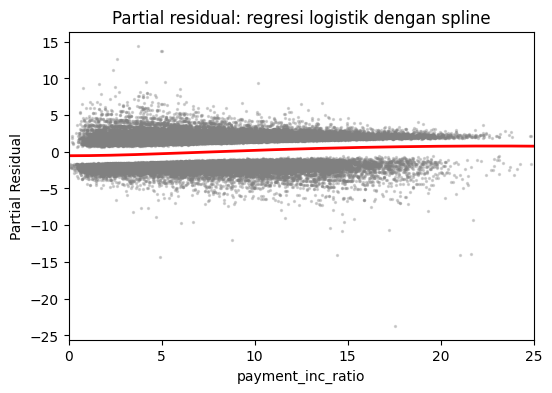

In [16]:
# Kontribusi suku spline payment_inc_ratio terhadap log-odds
exog = results.model.exog
names = results.model.exog_names
cols = [i for i, n in enumerate(names) if n.startswith('bs(payment_inc_ratio')]
term = exog[:, cols] @ results.params.values[cols]
term = term - term.mean()

partial_resid = results.resid_working + term

df_pr = pd.DataFrame({'payment_inc_ratio': loan_data['payment_inc_ratio'],
                      'terms': term, 'partial_resid': partial_resid})
df_pr = df_pr.sort_values('payment_inc_ratio')

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df_pr['payment_inc_ratio'], df_pr['partial_resid'], s=2, alpha=0.3, color='gray')
ax.plot(df_pr['payment_inc_ratio'], df_pr['terms'], color='red', lw=2)
ax.set_xlim(0, 25)
ax.set_xlabel('payment_inc_ratio')
ax.set_ylabel('Partial Residual')
ax.set_title('Partial residual: regresi logistik dengan spline')
plt.show()

**Interpretasi hasil:**
- Ringkasan `statsmodels` pada model linear (sel sebelumnya) cocok dengan ringkasan R pada buku: misalnya z-value `payment_inc_ratio` = 32,06 dan `borrower_score` = −55,20, deviance residual 57.515. Variabel `home_OWN` memiliki p-value 0,204 (tidak signifikan), sedangkan variabel lainnya sangat signifikan.
- Model dengan spline menurunkan deviance menjadi sekitar 57.487 (dari 57.515), peningkatan yang kecil. Artinya hubungan `payment_inc_ratio` dan `borrower_score` dengan log-odds default hanya sedikit nonlinear.
- Pada partial residual plot terlihat dua awan titik (atas: default, bawah: lunas) dengan garis fit di antaranya, persis pola yang dijelaskan buku untuk regresi logistik.

### Perbandingan regresi linear dan regresi logistik

| Aspek | Regresi linear | Regresi logistik |
|---|---|---|
| Bentuk | Parametrik linear antara prediktor dan respons | Parametrik linear pada skala log-odds |
| Pencarian model | Mirip (seleksi variabel, interaksi, spline) | Mirip |
| Cara fit | *Least squares* (ada solusi tertutup) | *Maximum likelihood* (iteratif) |
| Evaluasi | RMSE, $R^2$ | Metrik klasifikasi (accuracy, AUC, dan lain-lain) |
| Residual | Dapat bernilai 0 | Tidak pernah 0 (dua awan titik) |

---
## 4. Evaluating Classification Models

### Teori

Pada pemodelan prediktif, lazim melatih beberapa model, menerapkannya pada *holdout sample*, lalu menilai performanya. Jika data cukup, sampel holdout ketiga yang belum pernah dipakai digunakan untuk memperkirakan performa model terpilih pada data yang benar-benar baru.

**Istilah kunci**

| Istilah | Definisi |
|---|---|
| Accuracy | Persentase kasus yang diklasifikasikan benar |
| Confusion matrix | Tabel (2×2 pada kasus biner) jumlah record menurut prediksi dan kelas sebenarnya |
| Sensitivity / Recall | Persentase semua kelas 1 yang benar diklasifikasikan sebagai 1 |
| Specificity | Persentase semua kelas 0 yang benar diklasifikasikan sebagai 0 |
| Precision | Persentase prediksi 1 yang benar-benar 1 |
| ROC curve | Plot sensitivity terhadap specificity |
| Lift | Seberapa efektif model menemukan kelas 1 (yang relatif jarang) pada berbagai cutoff |

**Accuracy** adalah ukuran total error:

$$\text{accuracy}=\frac{\sum \text{TruePositive}+\sum \text{TrueNegative}}{\text{SampleSize}}$$

Cutoff bawaan umumnya 0,5. Alternatifnya adalah prevalensi kelas 1 dalam data.

**Confusion matrix** adalah inti metrik klasifikasi. Diagonalnya adalah prediksi benar, sisanya prediksi salah. Pada buku, baris adalah kelas sebenarnya dan kolom adalah prediksi (paket `caret` di R memakai urutan kebalikannya).

**Rare class problem.** Ketika satu kelas jauh lebih jarang (klaim asuransi palsu, pembeli di situs web), kelas langka itu biasanya yang lebih penting. Model yang selalu menebak kelas mayoritas bisa sangat akurat (misal 99,9%) tetapi tidak berguna. Maka dibutuhkan metrik selain accuracy.

**Precision, recall, dan specificity**

$$\text{precision}=\frac{TP}{TP+FP}\qquad \text{recall}=\frac{TP}{TP+FN}\qquad \text{specificity}=\frac{TN}{TN+FP}$$

Ketika kelas 1 langka, rasio false positive terhadap semua prediksi positif bisa tinggi, sehingga prediksi 1 kemungkinan besar sebenarnya 0. Inilah masalah pada tes skrining medis seperti mammografi.

**ROC curve** memplot *recall* (sumbu y) terhadap *specificity* (sumbu x) saat cutoff diubah. Ada *trade-off*: menangkap lebih banyak kelas 1 berarti salah mengklasifikasikan lebih banyak kelas 0 sebagai 1. Cara menghitungnya: urutkan record dari probabilitas 1 tertinggi ke terendah, lalu hitung recall dan specificity kumulatif. Garis diagonal setara tebakan acak. Classifier yang sangat baik mendekati sudut kiri atas.

**AUC** adalah luas area di bawah kurva ROC. AUC = 1 berarti sempurna, AUC = 0,5 berarti tidak lebih baik dari acak.

**Precision-Recall curve.** Dihitung mirip ROC, tetapi data diurutkan dari paling tidak mungkin ke paling mungkin dan dihitung precision serta recall kumulatif. Sangat berguna untuk data dengan outcome yang tidak seimbang.

**Lift.** AUC belum sepenuhnya menyelesaikan rare-case problem, karena pada kasus langka cutoff sering harus diturunkan jauh di bawah 0,5. Konsep *lift* menunda pertanyaan "cutoff optimal berapa?". Kita urutkan record dari probabilitas tertinggi, lalu bertanya: pada 10% teratas, seberapa lebih baik algoritma dibanding memilih secara acak? Jika respons di desil teratas adalah 0,3% dibanding 0,1% secara keseluruhan, maka *lift*-nya 3. *Lift chart* (gains chart) dibuat dari *cumulative gains* (recall terhadap jumlah record), lalu rasionya terhadap garis acak.

> **Uplift** kadang berarti sama dengan lift. Makna lain: pada A/B test, selisih respons yang diprediksi untuk satu kasus antara treatment A dan B.

### Kode: Confusion matrix

In [17]:
pred = logit_reg.predict(X)
pred_y = logit_reg.predict(X) == 'default'
true_y = y == 'default'
true_pos = true_y & pred_y
true_neg = ~true_y & ~pred_y
false_pos = ~true_y & pred_y
false_neg = true_y & ~pred_y

conf_mat = pd.DataFrame([[np.sum(true_pos), np.sum(false_neg)],
                         [np.sum(false_pos), np.sum(true_neg)]],
                        index=['Y = default', 'Y = paid off'],
                        columns=['Yhat = default', 'Yhat = paid off'])
conf_mat

,Yhat = default,Yhat = paid off
Y = default,14336,8335
Y = paid off,8148,14523


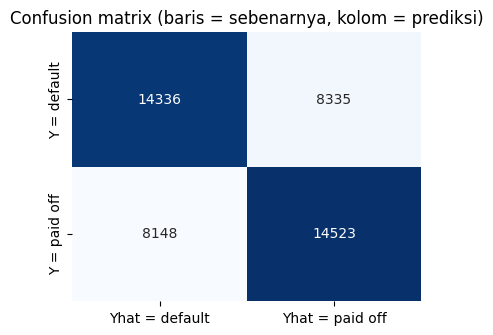

In [18]:
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
ax.set_title('Confusion matrix (baris = sebenarnya, kolom = prediksi)')
plt.show()

### Kode: Precision, recall, dan specificity

In [19]:
conf_mat = confusion_matrix(y, logit_reg.predict(X))
print('Precision  ', conf_mat[0, 0] / sum(conf_mat[:, 0]))
print('Recall     ', conf_mat[0, 0] / sum(conf_mat[0, :]))
print('Specificity', conf_mat[1, 1] / sum(conf_mat[1, :]))

precision_recall_fscore_support(y, logit_reg.predict(X),
                                labels=['default', 'paid off'])

Precision   0.6376089663760897
Recall      0.6323496978518812
Specificity 0.6405981209474659


(array([0.63760897, 0.63535742]),
 array([0.6323497 , 0.64059812]),
 array([0.63496844, 0.63796701]),
 array([22671, 22671]))

**Interpretasi hasil:**
- Dari 22.671 pinjaman default, 14.336 diprediksi benar dan 8.335 salah diprediksi lunas. Dari 22.671 pinjaman lunas, 14.523 diprediksi benar dan 8.148 salah diprediksi default.
- Accuracy = (14.336 + 14.523) / 45.342 ≈ **0,637**.
- Precision ≈ 0,638, recall ≈ 0,632, specificity ≈ 0,641. Ketiganya hampir sama karena data seimbang dan cutoff 0,5. Pada data tidak seimbang, ketiga angka ini bisa sangat berbeda.
- Angka confusion matrix di buku (14.295, 8.376, 8.052, 14.619) berasal dari model GAM pada R, sedangkan kode Python di buku memakai `logit_reg`, sehingga angkanya sedikit berbeda.

### Kode: ROC curve

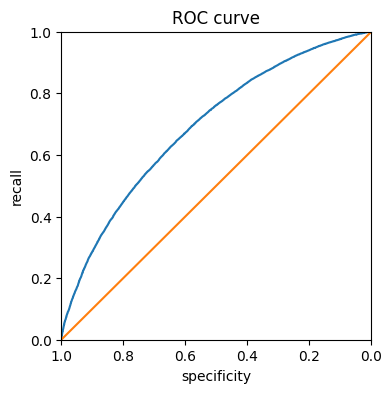

In [20]:
fpr, tpr, thresholds = roc_curve(y, logit_reg.predict_proba(X)[:, 0],
                                 pos_label='default')
roc_df = pd.DataFrame({'recall': tpr, 'specificity': 1 - fpr})

ax = roc_df.plot(x='specificity', y='recall', figsize=(4, 4), legend=False)
ax.set_ylim(0, 1)
ax.set_xlim(1, 0)
ax.plot((1, 0), (0, 1))
ax.set_xlabel('specificity')
ax.set_ylabel('recall')
ax.set_title('ROC curve')
plt.show()

### Kode: AUC

In [21]:
print(np.sum(roc_df.recall[:-1] * np.diff(1 - roc_df.specificity)))
print(roc_auc_score([1 if yi == 'default' else 0 for yi in y],
                    logit_reg.predict_proba(X)[:, 0]))

0.6917107972342917
0.6917108750592037


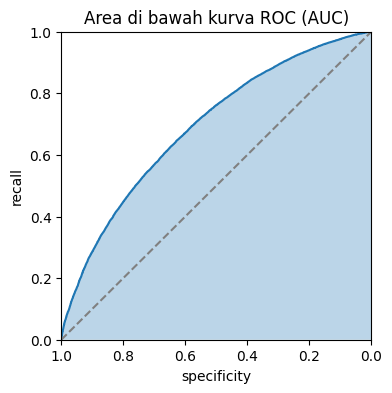

In [22]:
# Visualisasi area di bawah kurva ROC
fig, ax = plt.subplots(figsize=(4, 4))
ax.fill_between(roc_df.specificity, 0, roc_df.recall, alpha=0.3)
ax.plot(roc_df.specificity, roc_df.recall)
ax.plot((1, 0), (0, 1), ls='--', color='gray')
ax.set_xlim(1, 0); ax.set_ylim(0, 1)
ax.set_xlabel('specificity'); ax.set_ylabel('recall')
ax.set_title('Area di bawah kurva ROC (AUC)')
plt.show()

**Interpretasi hasil:**
- AUC dari integrasi numerik manual (**0,6917**) sama dengan `roc_auc_score` (**0,6917**), dan sesuai dengan nilai buku (0,6926 di R).
- AUC ≈ 0,69 menunjukkan classifier yang **relatif lemah**: lebih baik dari tebakan acak (0,5), tetapi jauh dari sempurna (1). Kurva ROC tidak mendekati sudut kiri atas.
- Hasil ini wajar. Data pinjaman bersifat *noisy*, dan hanya dengan variabel yang ada sulit memisahkan peminjam yang akan default dari yang tidak.

### Tambahan: Precision-Recall curve dan Lift/Gains chart
Dua bagian berikut **tidak ada kodenya di buku**. Buku hanya menjelaskan konsepnya (sidebar *Precision-Recall Curve* dan bagian *Lift*), jadi kodenya ditulis sendiri untuk mengilustrasikan konsep tersebut.

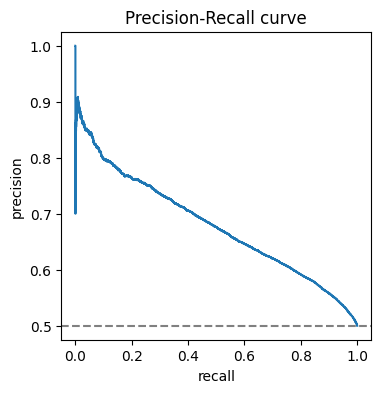

In [23]:
# Precision-Recall curve (kelas yang diminati = default)
prob_default = logit_reg.predict_proba(X)[:, 0]
precision, recall, _ = precision_recall_curve(true_y, prob_default)

fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(recall, precision)
ax.axhline(true_y.mean(), ls='--', color='gray')
ax.set_xlabel('recall'); ax.set_ylabel('precision')
ax.set_title('Precision-Recall curve')
plt.show()

In [24]:
# Lift per desil: urutkan dari probabilitas default tertinggi
lift_df = pd.DataFrame({'prob': prob_default, 'true': true_y.astype(int).values})
lift_df = lift_df.sort_values('prob', ascending=False).reset_index(drop=True)
lift_df['decile'] = pd.qcut(lift_df.index, 10, labels=range(1, 11))

lift_table = lift_df.groupby('decile', observed=True)['true'].agg(['sum', 'mean'])
lift_table.columns = ['jumlah default', 'respons desil']
lift_table['lift'] = lift_table['respons desil'] / lift_df['true'].mean()
lift_table['cumulative gains (recall)'] = lift_table['jumlah default'].cumsum() / lift_df['true'].sum()
lift_table.round(3)

,jumlah default,respons desil,lift,cumulative gains (recall)
decile,,,,
1,3532,0.779,1.558,0.156
2,3158,0.697,1.393,0.295
3,2827,0.624,1.247,0.420
4,2561,0.565,1.130,0.533
5,2346,0.517,1.035,0.636
6,2201,0.485,0.971,0.733
7,1969,0.434,0.869,0.820
8,1709,0.377,0.754,0.896
9,1403,0.309,0.619,0.957


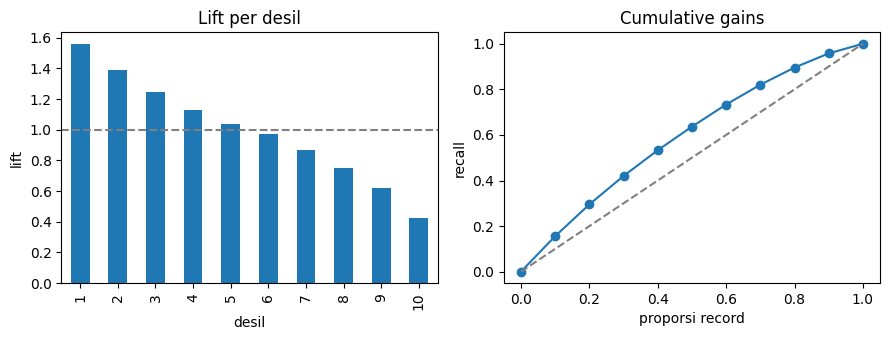

In [25]:
fig, axes = plt.subplots(ncols=2, figsize=(9, 3.5))
lift_table['lift'].plot(kind='bar', ax=axes[0], color='C0')
axes[0].axhline(1, color='gray', ls='--')
axes[0].set_title('Lift per desil'); axes[0].set_xlabel('desil'); axes[0].set_ylabel('lift')

gains = np.r_[0, lift_table['cumulative gains (recall)'].values]
axes[1].plot(np.arange(0, 11) / 10, gains, marker='o')
axes[1].plot([0, 1], [0, 1], ls='--', color='gray')
axes[1].set_title('Cumulative gains'); axes[1].set_xlabel('proporsi record'); axes[1].set_ylabel('recall')
plt.tight_layout(); plt.show()

**Interpretasi hasil (bagian tambahan):**
- Pada desil teratas (10% record dengan probabilitas default tertinggi), 77,9% pinjaman benar-benar default, dibanding 50% secara keseluruhan. Jadi **lift desil teratas ≈ 1,56**, dan lift terendah (desil 10) ≈ 0,43.
- Memilih 30% pinjaman teratas menangkap sekitar 42% dari seluruh pinjaman default (dibanding 30% bila memilih acak). Memilih 50% teratas menangkap sekitar 64%.
- Seperti AUC, lift yang hanya sekitar 1,56 menegaskan bahwa model ini cukup lemah. Kurva *cumulative gains* hanya sedikit di atas diagonal.

---
## 5. Strategies for Imbalanced Data

### Teori

Metrik non-accuracy membantu *mengevaluasi* model pada data tidak seimbang. Bagian ini membahas strategi untuk *memperbaiki* pemodelan pada data tidak seimbang, yaitu data yang outcome-nya diminati jarang muncul.

**Istilah kunci**
- **Undersample (downsample):** memakai lebih sedikit record kelas yang dominan.
- **Oversample (upsample):** memakai lebih banyak record kelas langka, dengan *bootstrap* jika perlu.
- **Up/down weight:** memberi bobot lebih besar (atau lebih kecil) pada kelas langka (atau dominan).
- **Data generation:** seperti bootstrap, tetapi tiap record baru sedikit berbeda dari sumbernya.

**Undersampling.** Jika data cukup, kurangi kelas dominan. Idenya: kelas dominan punya banyak record redundan, dan data yang lebih kecil dan seimbang memberi performa model yang lebih baik serta memudahkan eksplorasi. Umumnya puluhan ribu record kelas langka sudah cukup. Pada data penuh, hanya sekitar 19% pinjaman yang default. Jika model dilatih dengan seluruh data, pinjaman lunas "menenggelamkan" pinjaman default, sehingga model hampir tidak pernah memprediksi default.

**Oversampling dan up/down weighting.** Undersampling membuang data. Jika kelas langka hanya ratusan atau ribuan record, lebih baik **oversample** kelas langka dengan menarik baris tambahan *dengan pengembalian* (bootstrap). Efek serupa bisa dicapai dengan **pembobotan**: banyak algoritma menerima argumen bobot (`sample_weight` pada scikit-learn). Pada buku, bobot untuk kasus default adalah $1/p$ ($p$ = proporsi default), sedangkan kasus lunas berbobot 1, sehingga jumlah bobot kedua kelas kurang lebih sama.

> **Mengadaptasi loss function.** Sebagian literatur mengusulkan mengubah fungsi loss, tetapi dalam praktik sulit dilakukan. Pembobotan adalah cara mudah untuk mengubah loss, karena mengecilkan error pada record berbobot rendah dan menekankan record berbobot tinggi.

**Data generation dan SMOTE.** Variasi upsampling: buat record baru dengan *mengganggu* (perturb) record yang ada, supaya algoritma punya informasi lebih kaya untuk membangun aturan klasifikasi. **SMOTE** (*Synthetic Minority Oversampling Technique*) mencari record yang mirip (lewat KNN) dengan record yang di-upsample, lalu membuat record sintetis berupa rata-rata berbobot acak dari record asli dan tetangganya (bobot dihasilkan terpisah untuk tiap prediktor). Di Python tersedia paket `imbalanced-learn`.

**Cost-based classification.** Accuracy dan AUC hanya "cara orang miskin" memilih aturan klasifikasi. Seringkali biaya false positive dan false negative bisa diestimasi, sehingga lebih tepat memasukkan biaya itu saat menentukan cutoff. Misal biaya default pinjaman baru adalah $C$ dan keuntungan pinjaman lunas adalah $R$, maka:

$$\text{expected return}=P(Y=0)\times R+P(Y=1)\times C$$

Probabilitas default hanya langkah antara; ia harus digabung dengan nilai total pinjaman untuk menjadi laba yang diharapkan.

**Exploring the predictions.** Satu metrik seperti AUC tidak cukup menilai kecocokan model. Menggambar aturan keputusan beberapa model membantu memahami perilakunya (lihat bagian akhir).

### Kode: data penuh (tidak seimbang)

In [26]:
print('percentage of loans in default: ',
      100 * np.mean(full_train_set.outcome == 'default'))

percentage of loans in default:  18.894546909248504


In [27]:
predictors = ['payment_inc_ratio', 'purpose_', 'home_', 'emp_len_',
              'dti', 'revol_bal', 'revol_util']
outcome = 'outcome'
X = pd.get_dummies(full_train_set[predictors], prefix='', prefix_sep='',
                   drop_first=True, dtype=int)
y = full_train_set[outcome]

full_model = LogisticRegression(C=1e42, solver='liblinear')
full_model.fit(X, y)
print('percentage of loans predicted to default: ',
      100 * np.mean(full_model.predict(X) == 'default'))
X_full, y_full = X, y   # disimpan untuk contoh cost-based di bawah

percentage of loans predicted to default:  1.0134431230049923


### Kode: pembobotan (weighting)

In [28]:
default_wt = 1 / np.mean(full_train_set.outcome == 'default')
wt = [default_wt if outcome == 'default' else 1
      for outcome in full_train_set.outcome]

weighted_model = LogisticRegression(C=1e42, solver='liblinear')
weighted_model.fit(X, y, sample_weight=wt)
print('percentage of loans predicted to default (weighting): ',
      100 * np.mean(weighted_model.predict(X) == 'default'))

percentage of loans predicted to default (weighting):  61.075783209847735


**Interpretasi hasil:**
- Pada data penuh yang tidak seimbang (18,9% default), model biasa hanya memprediksi **1,0%** pinjaman sebagai default (buku: 0,39% di R dan sekitar 1% di Python). Pinjaman lunas "menenggelamkan" pinjaman default.
- Dengan pembobotan (bobot default = 1/p ≈ 5,3, bobot lunas = 1), persentase yang diprediksi default naik menjadi **61,1%** (buku: 57,7% di R). Jumlah bobot kedua kelas kini kira-kira seimbang, sehingga model tidak lagi mengabaikan kelas langka.
- Perbedaan kecil dengan angka buku muncul karena perbedaan implementasi R dan Python.

### Tambahan: oversampling (bootstrap) dan SMOTE dengan `imbalanced-learn`
Buku hanya menyebut paket ini, tidak menampilkan kodenya. Bagian ini adalah **tambahan** untuk membandingkan strategi lain pada data yang sama.

In [29]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

samplers = {
    'undersample': RandomUnderSampler(random_state=1),
    'oversample (bootstrap)': RandomOverSampler(random_state=1),
    'SMOTE': SMOTE(random_state=1),
}

rows = []
for name, sampler in samplers.items():
    X_res, y_res = sampler.fit_resample(X, y)
    model = LogisticRegression(C=1e42, solver='liblinear').fit(X_res, y_res)
    rows.append({
        'strategi': name,
        'jumlah data latih': len(y_res),
        '% default pada data latih': 100 * np.mean(y_res == 'default'),
        '% diprediksi default (data asli)': 100 * np.mean(model.predict(X) == 'default'),
    })
pd.DataFrame(rows).round(2)

,strategi,jumlah data latih,% default pada data latih,% diprediksi default (data asli)
0,undersample,45342,50.0,42.63
1,oversample (bootstrap),194632,50.0,42.80
2,SMOTE,194632,50.0,29.25


**Interpretasi hasil (bagian tambahan):**
- Ketiga strategi mengatasi masalah utama: persentase pinjaman yang diprediksi default naik dari sekitar 1% (tanpa penanganan) menjadi puluhan persen.
- *Undersample* dan *oversample (bootstrap)* memberi hasil hampir sama (±43%). Undersampling membuang data (hanya sekitar 45 ribu baris tersisa), sedangkan oversampling menduplikasi baris kelas langka (sekitar 195 ribu baris).
- SMOTE memberi angka lebih rendah (±29%). Salah satu penyebabnya, SMOTE melakukan interpolasi antar tetangga pada kolom dummy sehingga menghasilkan nilai pecahan (misal 0,4 untuk variabel yang seharusnya 0 atau 1), yang tidak bermakna untuk variabel kategorikal. Untuk data campuran numerik dan kategorikal, `imbalanced-learn` menyediakan varian `SMOTENC`.
- Persentase prediksi default di sini dihitung pada **seluruh data asli** (19% default), sehingga tidak harus mendekati 50%.

### Tambahan: ilustrasi cost-based classification
Buku hanya memberi rumus. Ilustrasi berikut memakai **asumsi angka buatan sendiri** (bukan dari data atau buku): keuntungan pinjaman lunas $R$ = 10% dari nilai pinjaman dan kerugian pinjaman default $C$ = −50% dari nilai pinjaman. Probabilitas default diambil dari model regresi logistik pada **data penuh** (base rate default sekitar 19%), bukan dari model pada data seimbang, karena model pada data seimbang melebih-lebihkan probabilitas default.

Dengan asumsi tersebut, expected return bernilai positif hanya jika $(1-p)R + pC > 0$, yaitu $p < \frac{R}{R + |C|} = \frac{0{,}10}{0{,}10 + 0{,}50} \approx 0{,}167$. Jadi cutoff yang masuk akal secara bisnis adalah sekitar 0,167, bukan 0,5.

In [30]:
sample_idx = full_train_set.sample(6, random_state=3).index
sample = full_train_set.loc[sample_idx]

# kolom 0 pada predict_proba = 'default' (urutan abjad)
p_default = full_model.predict_proba(X_full.loc[sample_idx])[:, 0]
R = 0.10 * sample['loan_amnt'].values     # asumsi: keuntungan jika lunas
C = -0.50 * sample['loan_amnt'].values    # asumsi: kerugian jika default

cost_df = pd.DataFrame({
    'loan_amnt': sample['loan_amnt'].values,
    'P(default)': p_default.round(3),
    'expected return': ((1 - p_default) * R + p_default * C).round(0),
}, index=sample_idx)
cost_df['keputusan'] = np.where(cost_df['expected return'] > 0, 'setujui', 'tolak')
print('titik impas P(default) =', round(0.10 / (0.10 + 0.50), 3))
cost_df

titik impas P(default) = 0.167


,loan_amnt,P(default),expected return,keputusan
15128,3500,0.154,26.0,setujui
63708,11100,0.212,-301.0,tolak
47200,24000,0.277,-1582.0,tolak
61539,16425,0.238,-708.0,tolak
43042,8000,0.111,269.0,setujui
108961,12000,0.201,-244.0,tolak


**Interpretasi hasil:**
- Dengan asumsi R = +10% dan C = −50% dari nilai pinjaman, titik impas probabilitas default adalah sekitar **0,167**. Pinjaman dengan P(default) di bawah angka itu (misalnya 0,154 dan 0,111) memiliki expected return positif dan disetujui. Pinjaman dengan P(default) di atasnya (0,20 sampai 0,28) ditolak.
- Perhatikan bahwa nilai pinjaman ikut menentukan besarnya untung atau rugi. Inilah maksud buku bahwa probabilitas default hanya langkah antara dan harus digabung dengan nilai pinjaman untuk menjadi ukuran bisnis yang sebenarnya.
- Angka R dan C di atas hanya asumsi untuk ilustrasi, bukan nilai dari data.

### Kode: Exploring the predictions (Figure 5-8)

Gambar berikut membandingkan batas keputusan empat model pada data `loan3000` dengan dua prediktor: **LDA**, **regresi logistik linear**, **regresi logistik dengan spline (GAM)**, dan **pohon keputusan**. Buku menampilkan gambar ini tanpa kodenya, jadi kodenya ditulis sendiri.

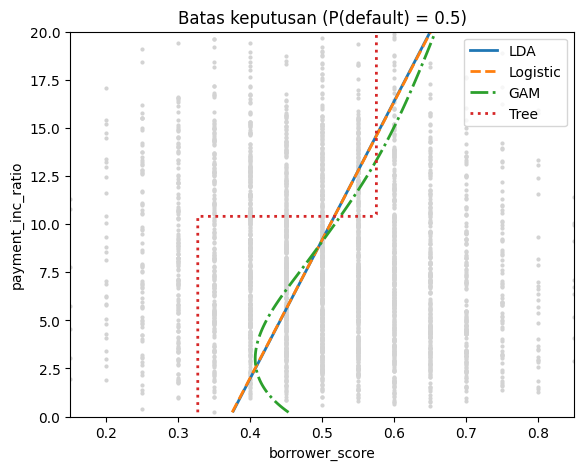

In [31]:
predictors = ['borrower_score', 'payment_inc_ratio']
X3 = loan3000[predictors]
y3 = loan3000['outcome']
loan3000_g = loan3000.assign(is_default=(loan3000['outcome'] == 'default').astype(int))

lda_m = LinearDiscriminantAnalysis().fit(X3, y3)
logit_m = LogisticRegression(C=1e42, solver='liblinear').fit(X3, y3)
tree_m = DecisionTreeClassifier(random_state=1, criterion='entropy',
                                min_impurity_decrease=0.003).fit(X3, y3)
gam_m = smf.glm('is_default ~ bs(borrower_score, df=4) + bs(payment_inc_ratio, df=4)',
                data=loan3000_g, family=sm.families.Binomial()).fit()

# spline bs() tidak bisa memprediksi di luar rentang data latih, jadi grid dibatasi ke rentang data
xx, yy = np.meshgrid(np.linspace(X3.borrower_score.min(), X3.borrower_score.max(), 300),
                     np.linspace(X3.payment_inc_ratio.min(), X3.payment_inc_ratio.max(), 300))
grid = pd.DataFrame({'borrower_score': xx.ravel(), 'payment_inc_ratio': yy.ravel()})

p_lda = lda_m.predict_proba(grid)[:, list(lda_m.classes_).index('default')]
p_log = logit_m.predict_proba(grid)[:, list(logit_m.classes_).index('default')]
p_tree = tree_m.predict_proba(grid)[:, list(tree_m.classes_).index('default')]
p_gam = gam_m.predict(grid)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(loan3000.borrower_score, loan3000.payment_inc_ratio, s=4, color='lightgray')
from matplotlib.lines import Line2D
handles = []
for (p, label, style), color in zip([(p_lda, 'LDA', '-'), (p_log, 'Logistic', '--'),
                                     (p_gam, 'GAM', '-.'), (p_tree, 'Tree', ':')],
                                    ['C0', 'C1', 'C2', 'C3']):
    ax.contour(xx, yy, np.asarray(p).reshape(xx.shape), levels=[0.5],
               colors=color, linestyles=style, linewidths=2)
    handles.append(Line2D([0], [0], color=color, ls=style, lw=2, label=label))
ax.set_xlim(0.15, 0.85); ax.set_ylim(0, 20)
ax.set_xlabel('borrower_score'); ax.set_ylabel('payment_inc_ratio')
ax.set_title('Batas keputusan (P(default) = 0.5)')
ax.legend(handles=handles)
plt.show()

**Interpretasi hasil:**
- Garis **LDA** dan **regresi logistik linear** hampir berimpit (garis oranye tertutup garis biru), sama dengan temuan buku bahwa keduanya memberi hasil nyaris identik pada kasus ini.
- **Pohon keputusan** menghasilkan aturan paling tidak beraturan, dengan batas berundak yang terdiri dari beberapa persegi panjang.
- **GAM** (regresi logistik dengan spline) merupakan kompromi antara model linear dan pohon: batasnya melengkung mengikuti data, terutama di bagian bawah plot.
- Pelajaran dari gambar ini: satu metrik seperti AUC tidak cukup. Melihat bentuk aturan keputusan membantu memahami perilaku model, dan analisis eksploratif atas prediksi selalu perlu dilakukan.

---
## Key Ideas (Rangkuman Chapter 5)

**Naive Bayes**
- Bekerja dengan prediktor dan outcome kategorikal.
- Bertanya: "Dalam tiap kategori outcome, kategori prediktor mana yang paling mungkin?", lalu informasi itu dibalik untuk mengestimasi probabilitas outcome.

**Discriminant Analysis**
- Bekerja dengan prediktor kontinu atau kategorikal dan outcome kategorikal.
- Memakai matriks kovarians untuk menghitung fungsi diskriminan linear yang membedakan kelas.
- Fungsi ini menghasilkan skor untuk tiap record yang menentukan kelas yang diestimasi.

**Logistic Regression**
- Seperti regresi linear, tetapi outcome-nya biner, dengan log odds sebagai respons.
- Model dilatih secara iteratif (MLE), lalu log odds dipetakan kembali menjadi probabilitas.
- Populer karena cepat dan model mudah dipakai untuk men-skor data baru dengan sedikit operasi aritmetika.

**Evaluating Classification Models**
- Accuracy hanya langkah pertama evaluasi.
- Recall, specificity, dan precision menyoroti karakteristik performa yang lebih spesifik.
- AUC mengukur kemampuan model membedakan 1 dari 0.
- Lift mengukur efektivitas model menemukan kelas 1, biasanya per desil mulai dari yang paling mungkin 1.

**Imbalanced Data**
- Data yang sangat tidak seimbang bermasalah bagi algoritma klasifikasi.
- Strategi: undersample kelas melimpah, oversample kelas langka, bootstrap atau SMOTE bila perlu.
- Ketidakseimbangan biasanya menandakan bahwa mengklasifikasi kelas 1 dengan benar lebih bernilai, dan rasio nilai itu harus masuk ke metrik evaluasi.

## Referensi
- Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists*, 2nd ed. O'Reilly. Chapter 5.
- Hastie, Tibshirani, & Friedman. *The Elements of Statistical Learning*, 2nd ed. Springer, 2009.
- Chawla et al. (2002). "SMOTE: Synthetic Minority Over-sampling Technique." *JAIR* 16: 321–357.
- Kode dan dataset sumber: https://github.com/gedeck/practical-statistics-for-data-scientists